# Treinamento do YOLO G5 — o detector escolhido pelo repositório

Treina **uma única variante**: a **G5** de `MODELS/TESTES_RECORTES_YOLO_CONVNEXT/yolo_gpu/treinar_yolo_gpu.py`, a que o
repositório escolheu na **validação** (critério `AP50 + recall de objetos pequenos`) e usou no fluxo final.
Detector de **classe única** (`object`): localiza o objeto sem dizer se é MILCO ou NOMBO.

| Item | Valor (idêntico ao repositório) |
|---|---|
| Modelo | YOLOv8s com cabeça **P2** (`yolov8s-p2.yaml`) + pesos COCO `yolov8s.pt` |
| Entrada | **1024 px**, batch 8 |
| Classe única | `single_cls=True` (rótulos MILCO/NOMBO viram `object`) |
| Augmentação p/ objetos pequenos | `mosaic=0.3`, `copy_paste=0.3`, `scale=0.3`, `flipud=0.0` |
| Demais | `patience=50`, `seed=42`, split 70/15/15 (819/175/176 imagens) |

**Resultado de referência no repositório** (2× Tesla T4, 221 épocas em 2,5 h): AP50 de validação **0,693**,
AP50 de teste **0,722**, recall de pequenos (val) **0,623**. O notebook imprime os seus números ao lado desses.

> **Sobre "o melhor":** o G5 é o melhor *pelo critério de validação do repositório*. No teste, a G1 (YOLOv8n-P2, 640 px)
> teve AP50 um pouco maior (0,758 contra 0,722), mas com 109 objetos no teste essa diferença está dentro do ruído, e o
> repositório não escolhe pelo teste. O melhor resultado de detecção do repositório veio de **G5 + TTA fundido (WBF) com
> o seu Modelo A** — isso é inferência, sem novo treino, e está na Seção 8 (opcional).

## 1. Imports

In [1]:
# !pip install "ultralytics>=8.3" pandas matplotlib pillow
# (instale antes o PyTorch com CUDA: https://pytorch.org/get-started/locally/)
import os, gc, json, shutil, time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from PIL import Image
import ultralytics
from ultralytics import YOLO

pd.set_option("display.precision", 3); pd.set_option("display.width", 200)
print("Ultralytics", ultralytics.__version__, "| torch", torch.__version__)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "nenhuma (CPU)")

Ultralytics 8.4.163 | torch 2.14.0+cu126
GPU: NVIDIA GeForce RTX 3050


## 2. Configuração

**Duração do treino.** No repositório o G5 rodou com teto de **2,5 h** e completou **221 épocas** (T4 ≈ 41 s/época).
O número de épocas então dependia da velocidade da GPU. Aqui o padrão é fixar **`EPOCHS = 220`** (reproduz o
mesmo número de épocas, qualquer que seja a GPU). Se preferir limitar por tempo, defina `HORAS_TREINO` (ex.: 2.5);
nesse caso o ultralytics ignora `EPOCHS` e ajusta o decaimento da taxa de aprendizado ao orçamento de tempo.

**GPU de 8 GB (ex.: RTX 3050).** Com 1024 px e batch 8 pode faltar memória: o notebook reduz o batch pela metade
automaticamente se ocorrer `out of memory`.

In [2]:
# ----------------------------------------------------------------------------- pastas
PROJETO_DIR = Path("D:/testte/data-science-notebooks/MODELS/TESTE_YOLO_G5")     # <-- saída deste notebook
SAIDA = PROJETO_DIR / "saida"
DATASET_EXISTENTE = Path("D:/testte/SEPARACAO_MODELS/TESTE_BOX_YOLO/work/yolo_dataset")   # images/{train,val,test} + labels/...

# ----------------------------------------------------------------------------- treino (G5 = receita do repositório)
NOME = "G5"
MODELO_YAML, PESOS_INICIAIS, IMGSZ = "yolov8s-p2.yaml", "yolov8s.pt", 1024
EXTRA_G5 = dict(mosaic=0.3, copy_paste=0.3, scale=0.3, flipud=0.0)        # augmentação p/ objetos pequenos

EPOCHS = 200                       # o repositório rodou 221 épocas
HORAS_TREINO = 0                   # 0 = usa EPOCHS; ex.: 2.5 = teto de tempo (ignora EPOCHS)
BATCH = 8                          # regra do repositório para 1024 px; cai pela metade sozinho se faltar memória
CACHE_RAM = False                  # True acelera, mas consome RAM (seu kernel já caiu por RAM antes)
WORKERS = 0 if os.name == "nt" else 4   # Windows + Jupyter: 0 evita travamentos do DataLoader
SMOKE = False                      # True = teste rápido (1 época, 320 px, 10% dos dados)
SEED = 42
DEVICE = 0 if torch.cuda.is_available() else "cpu"

# ----------------------------------------------------------------------------- opcional (Seção 8)
RODAR_TTA_WBF = False              # TTA e fusão WBF com o seu Modelo A (só inferência)
PESOS_MODELO_A = Path("D:/testte/SEPARACAO_MODELS/TESTE_BOX_YOLO/runs/detect/work/runs/modelA_yolo_p2/weights/best.pt")
IMGSZ_MODELO_A = 640

# referência do repositório (G5, 2x T4) para comparação
REF_REPO = {"val": {"AP50": 0.693, "recall@0.25": 0.667, "precisao@0.25": 0.735, "FP_por_imagem@0.25": 0.103, "recall_pequenos@0.25": 0.623},
            "test": {"AP50": 0.722, "recall@0.25": 0.633, "precisao@0.25": 0.726, "FP_por_imagem@0.25": 0.148, "recall_pequenos@0.25": 0.574}}

SAIDA.mkdir(parents=True, exist_ok=True)
(SAIDA / "pesos").mkdir(exist_ok=True)
print("Saída:", SAIDA)

Saída: D:\testte\data-science-notebooks\MODELS\TESTE_YOLO_G5\saida


## 3. Dataset em classe única

Usa o seu `yolo_dataset` **sem alterá-lo** (o ultralytics só grava os `.cache` de rótulos dentro dele, como já fazia). O
`saida/data_object.yaml` declara uma única classe `object`, e `single_cls=True` junta as classes dos rótulos.

In [3]:
IMG_EXT = {".jpg", ".jpeg", ".png"}
SPLITS = ("train", "val", "test")

DS = Path(DATASET_EXISTENTE)
for s in SPLITS:
    assert (DS / "images" / s).exists(), f"Não encontrei {DS / 'images' / s}. Ajuste DATASET_EXISTENTE."


def listar_imagens(split):
    d = DS / "images" / split
    return sorted([p for p in d.iterdir() if p.suffix.lower() in IMG_EXT], key=lambda p: p.name)


def carregar_gts(split):
    """{stem: [[x1,y1,x2,y2] em pixels]} — a classe do rótulo é ignorada (objeto único)."""
    gts = {}
    for img in listar_imagens(split):
        w, h = Image.open(img).size
        lab = DS / "labels" / split / f"{img.stem}.txt"
        g = []
        if lab.exists():                                  # sem arquivo = imagem de fundo
            for l in lab.read_text().splitlines():
                q = l.split()
                if len(q) == 5:
                    xc, yc, bw, bh = map(float, q[1:])
                    g.append([(xc - bw / 2) * w, (yc - bh / 2) * h, (xc + bw / 2) * w, (yc + bh / 2) * h])
        gts[img.stem] = g
    return gts


DATA_YAML = SAIDA / "data_object.yaml"
DATA_YAML.write_text(f"path: {DS.resolve().as_posix()}\ntrain: images/train\nval: images/val\ntest: images/test\nnames:\n  0: object\n")

GTS = {s: carregar_gts(s) for s in SPLITS}
linhas = []
for s in SPLITS:
    g = GTS[s]
    areas = [(b[2] - b[0]) * (b[3] - b[1]) for v in g.values() for b in v]
    linhas.append({"split": s, "imagens": len(g), "com_objeto": sum(len(v) > 0 for v in g.values()),
                   "fundo": sum(len(v) == 0 for v in g.values()), "objetos": len(areas),
                   "pequenos(<32²px)": sum(a < 32 * 32 for a in areas)})
ESTAT = pd.DataFrame(linhas).set_index("split")
print("Dataset:", DS, "\ndata.yaml:", DATA_YAML)
display(ESTAT)
if {s: int(ESTAT.loc[s, "imagens"]) for s in SPLITS} != {"train": 819, "val": 175, "test": 176}:
    print("AVISO: o split difere do repositório (819/175/176); os resultados não serão diretamente comparáveis.")

Dataset: D:\testte\SEPARACAO_MODELS\TESTE_BOX_YOLO\work\yolo_dataset 
data.yaml: D:\testte\data-science-notebooks\MODELS\TESTE_YOLO_G5\saida\data_object.yaml


,imagens,com_objeto,fundo,objetos,pequenos(<32²px)
split,,,,,
train,819,217,602,484,304
val,175,41,134,75,53
test,176,46,130,109,68


## 4. Avaliador de detecção (porta do `avaliar` do repositório)

AP50 (IoU 0,5, todos os pontos), recall/precisão/falsos positivos por imagem em conf 0,25 e **recall de objetos pequenos**
(< 32² px). Predições coletadas com `conf=0.001`. Verificado contra o `avaliar` original em dados sintéticos.

In [4]:
def iou_xyxy(a, b):
    x1, y1, x2, y2 = max(a[0], b[0]), max(a[1], b[1]), min(a[2], b[2]), min(a[3], b[3])
    inter = max(0.0, x2 - x1) * max(0.0, y2 - y1)
    return inter / ((a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter + 1e-9)


def nms_np(b, iou_thr):
    """NMS guloso por confiança. b: [N,5] = x1,y1,x2,y2,conf."""
    if len(b) == 0:
        return b
    manter = []
    for i in np.argsort(-b[:, 4]):
        if all(iou_xyxy(b[i, :4], b[j, :4]) <= iou_thr for j in manter):
            manter.append(i)
    return b[manter]


def coletar_deteccoes(model, split, imgsz, augment=False, iou=0.6):
    """{stem: [N,5]} (x1,y1,x2,y2,conf) com conf >= 0.001."""
    out = {}
    for img in listar_imagens(split):
        r = model.predict(str(img), imgsz=imgsz, conf=0.001, iou=iou, augment=augment, device=DEVICE, verbose=False)[0]
        out[img.stem] = (np.concatenate([r.boxes.xyxy.cpu().numpy(), r.boxes.conf.cpu().numpy()[:, None]], 1)
                         if len(r.boxes) else np.zeros((0, 5)))
    return out


def metricas_deteccao(dets, gts, conf_op=0.25, iou_nms=None):
    n_gt = n_small = tp_small = tp_op = fp_op = 0
    pares = []
    for stem, g in gts.items():
        n_gt += len(g)
        d = dets.get(stem)
        d = np.zeros((0, 5)) if d is None else d
        if iou_nms is not None:
            d = nms_np(d, iou_nms)
        d = d[np.argsort(-d[:, 4])] if len(d) else d
        usado, usado_op = set(), set()
        for b in d:
            j = max(range(len(g)), key=lambda k: iou_xyxy(b[:4], g[k]), default=None)
            ok = j is not None and j not in usado and iou_xyxy(b[:4], g[j]) >= 0.5
            if ok:
                usado.add(j)
            pares.append((b[4], ok))
            if b[4] >= conf_op:
                if ok:
                    tp_op += 1; usado_op.add(j)
                else:
                    fp_op += 1
        for k, gb in enumerate(g):
            if (gb[2] - gb[0]) * (gb[3] - gb[1]) < 32 * 32:
                n_small += 1
                tp_small += k in usado_op
    pares.sort(key=lambda t: -t[0])
    oks = np.array([o for _, o in pares], dtype=float)
    ctp, cfp = np.cumsum(oks), np.cumsum(1 - oks)
    rec, prec = ctp / max(n_gt, 1), ctp / np.maximum(ctp + cfp, 1e-9)
    mrec, mpre = np.r_[0, rec, 1], np.r_[1, prec, 0]
    for i in range(len(mpre) - 2, -1, -1):
        mpre[i] = max(mpre[i], mpre[i + 1])
    return {"AP50": float(np.sum((mrec[1:] - mrec[:-1]) * mpre[1:])), "conf": conf_op,
            "recall": tp_op / max(n_gt, 1), "precisao": tp_op / max(tp_op + fp_op, 1),
            "FP_por_img": fp_op / max(len(gts), 1), "recall_pequenos": tp_small / max(n_small, 1),
            "n_objetos": n_gt, "n_pequenos": n_small}


def avaliar_modelo(model, split, imgsz):
    """Mesmas chaves do resultados_yolo_gpu.csv do repositório (conf 0,25)."""
    m = metricas_deteccao(coletar_deteccoes(model, split, imgsz), GTS[split], 0.25)
    return {"AP50": m["AP50"], "recall@0.25": m["recall"], "precisao@0.25": m["precisao"],
            "FP_por_imagem@0.25": m["FP_por_img"], "recall_pequenos@0.25": m["recall_pequenos"],
            "n_objetos": m["n_objetos"], "n_pequenos": m["n_pequenos"]}


def limpar_gpu():
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

## 5. Treino do G5

Retomável: se o kernel cair ou você interromper, rode a célula de novo — ela continua do `last.pt`. Se o treino já
terminou (`FEITO.json`), só recarrega os resultados. Ao final, avalia validação e teste e salva
`saida/pesos/G5_best.pt`.

In [5]:
def _eh_oom(e):
    return isinstance(e, torch.cuda.OutOfMemoryError) or "out of memory" in str(e).lower()


def treinar_g5():
    run = SAIDA / "runs" / NOME
    feito, last, best = run / "FEITO.json", run / "weights" / "last.pt", run / "weights" / "best.pt"
    if feito.exists():
        print(f"[{NOME}] já concluído (FEITO.json) - carregando resultados")
        return json.load(open(feito))

    imgsz = 320 if SMOKE else IMGSZ
    batch = BATCH
    t0 = time.time()
    while True:
        kw = dict(data=str(DATA_YAML), epochs=1 if SMOKE else EPOCHS, imgsz=imgsz, batch=batch, device=DEVICE,
                  single_cls=True, mosaic=0.0, flipud=0.0, patience=50, project=str(SAIDA / "runs"), name=NOME,
                  exist_ok=True, seed=SEED, workers=0 if SMOKE else WORKERS, plots=not SMOKE)
        if HORAS_TREINO > 0:
            kw["time"] = HORAS_TREINO
        if CACHE_RAM:
            kw["cache"] = "ram"
        if SMOKE:
            kw["fraction"] = 0.1
        kw.update(EXTRA_G5)                                   # mosaic/copy_paste/scale/flipud do G5
        model = None
        try:
            if last.exists() and not SMOKE:
                print(f"[{NOME}] retomando de {last}")
                model = YOLO(str(last))
                model.train(resume=True)
            else:
                print(f"[{NOME}] treinando: {MODELO_YAML} | imgsz={imgsz} | batch={batch} | "
                      f"{'tempo=' + str(HORAS_TREINO) + ' h' if HORAS_TREINO > 0 else 'epocas=' + str(kw['epochs'])} | extra={EXTRA_G5}")
                model = YOLO(MODELO_YAML)
                model.load(PESOS_INICIAIS)                    # pesos COCO nas camadas compatíveis
                model.train(**kw)
            break
        except Exception as e:
            msg = str(e).lower()
            if "nothing to resume" in msg or "is finished" in msg:
                print(f"[{NOME}] o treino já havia terminado; seguindo para a avaliação")
                break
            if _eh_oom(e) and batch > 2 and not last.exists():
                batch //= 2
                print(f"[{NOME}] sem memória de GPU -> tentando com batch={batch}")
                model = None
                limpar_gpu()
                continue
            raise
    del model
    limpar_gpu()

    assert best.exists(), f"best.pt não encontrado em {best}"
    modelo = YOLO(str(best))
    res = {"variante": NOME, "modelo": MODELO_YAML, "imgsz": imgsz, "batch": batch, "extra": EXTRA_G5,
           "epocas_pedidas": EPOCHS, "horas_teto": HORAS_TREINO, "treino_min": round((time.time() - t0) / 60, 1),
           "val": avaliar_modelo(modelo, "val", imgsz), "test": avaliar_modelo(modelo, "test", imgsz)}
    shutil.copy(best, SAIDA / "pesos" / f"{NOME}_best.pt")
    json.dump(res, open(feito, "w"), indent=1)
    del modelo
    limpar_gpu()
    return res


RES = treinar_g5()
PESOS_G5 = SAIDA / "pesos" / f"{NOME}_best.pt"
print(f"\nPesos: {PESOS_G5} | treino (esta sessão): {RES['treino_min']} min | batch usado: {RES['batch']}")

[G5] treinando: yolov8s-p2.yaml | imgsz=1024 | batch=8 | epocas=200 | extra={'mosaic': 0.3, 'copy_paste': 0.3, 'scale': 0.3, 'flipud': 0.0}
Transferred 219/437 items from pretrained weights
New https://pypi.org/project/ultralytics/8.4.192 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.163  Python-3.11.9 torch-2.14.0+cu126 CUDA:0 (NVIDIA GeForce RTX 3050, 8192MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.3, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=D:\testte\data-science-notebooks\MODELS\TESTE_YOLO_G5\saida\data_object.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=200, erasing=0.4, exist_ok=True, f

C:\Users\Usuário\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


albumentations: Blur(p=0.01, blur_limit=(3, 7)), MedianBlur(p=0.01, blur_limit=(3, 7)), ToGray(p=0.01, method='weighted_average', num_output_channels=3), CLAHE(p=0.01, clip_limit=(1.0, 4.0), tile_grid_size=(8, 8))
WARNING val: Slow image access detected (ping: 0.20.1 ms, read: 12.612.2 MB/s, size: 146.6 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning D:\testte\SEPARACAO_MODELS\TESTE_BOX_YOLO\work\yolo_dataset\labels\val.cache... 175 images, 134 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 175/175  0.0s
optimizer: 'optimizer=auto' found, ignoring 'lr0=0.01' and 'momentum=0.937' and determining best 'optimizer', 'lr0' and 'momentum' automatically... 
optimizer: AdamW(lr=0.002, momentum=0.9) with parameter groups 70 weight(decay=0.0), 79 weight(decay=0.0005), 78 bias(decay=0.0)
Plotting labels to D:\testte\data-science-notebooks\MODELS\TESTE_YOLO_G5\saida\runs\G5\labels.jpg... 
Using 81

## 6. Resultados (você × repositório) e curvas de treino

As escolhas (variante, conf, IoU do NMS) são feitas na **validação**; o teste só reporta. Com 109 objetos no teste,
diferenças de poucos pontos entre execuções são normais — o treino em outra GPU não reproduz os números do
repositório exatamente.

AP50  recall@0.25  precisao@0.25  FP_por_imagem@0.25  recall_pequenos@0.25
split     quem                                                                                               
validação você                    0.730        0.640          0.873               0.040                 0.623
          repositório (G5, 2×T4)  0.693        0.667          0.735               0.103                 0.623
teste     você                    0.715        0.688          0.798               0.108                 0.676
          repositório (G5, 2×T4)  0.722        0.633          0.726               0.148                 0.574

Critério de escolha do repositório (val: AP50 + recall de pequenos): você 1.353 | repositório 1.316


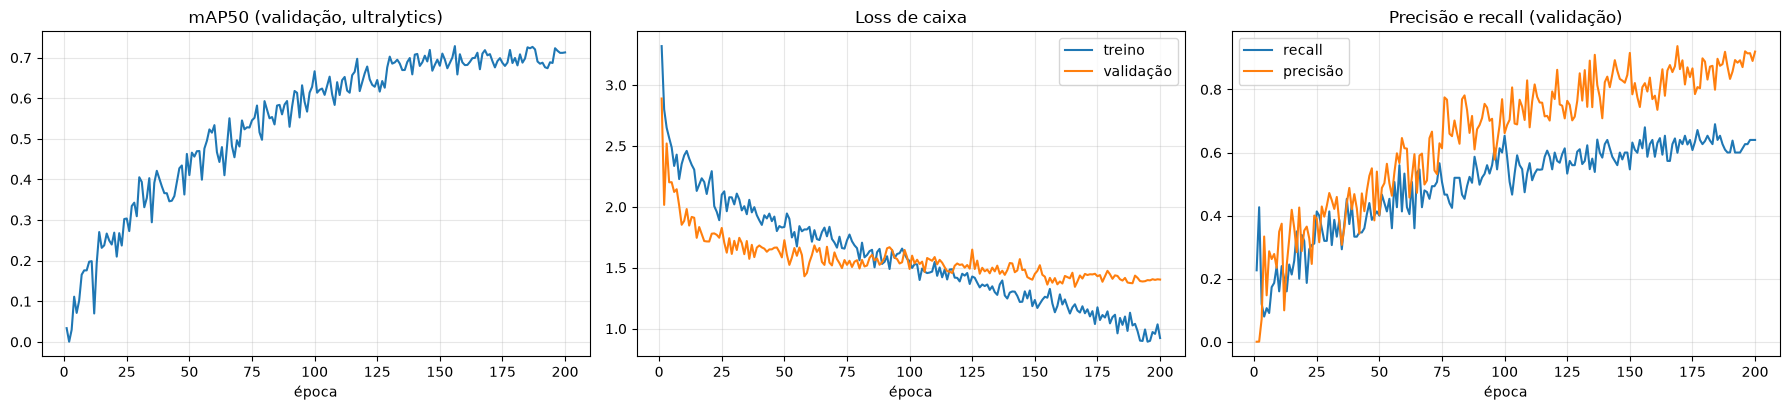

Épocas rodadas: 200 | melhor mAP50 na época 156


In [6]:
linhas = []
for sp, rot in (("val", "validação"), ("test", "teste")):
    for quem, fonte in (("você", RES[sp]), ("repositório (G5, 2×T4)", REF_REPO[sp])):
        linhas.append({"split": rot, "quem": quem, **{k: fonte[k] for k in ("AP50", "recall@0.25", "precisao@0.25",
                                                                           "FP_por_imagem@0.25", "recall_pequenos@0.25")}})
display(pd.DataFrame(linhas).set_index(["split", "quem"]))
print("Critério de escolha do repositório (val: AP50 + recall de pequenos): "
      f"você {RES['val']['AP50'] + RES['val']['recall_pequenos@0.25']:.3f} | repositório {0.693 + 0.623:.3f}")

f = SAIDA / "runs" / NOME / "results.csv"
if f.exists():
    df = pd.read_csv(f); df.columns = df.columns.str.strip()
    fig, axs = plt.subplots(1, 3, figsize=(18, 4.2))
    axs[0].plot(df["epoch"], df["metrics/mAP50(B)"]); axs[0].set_title("mAP50 (validação, ultralytics)")
    axs[1].plot(df["epoch"], df["train/box_loss"], label="treino"); axs[1].plot(df["epoch"], df["val/box_loss"], label="validação")
    axs[1].set_title("Loss de caixa"); axs[1].legend()
    axs[2].plot(df["epoch"], df["metrics/recall(B)"], label="recall"); axs[2].plot(df["epoch"], df["metrics/precision(B)"], label="precisão")
    axs[2].set_title("Precisão e recall (validação)"); axs[2].legend()
    for a in axs:
        a.set_xlabel("época"); a.grid(alpha=0.3)
    plt.tight_layout(); plt.show()
    print(f"Épocas rodadas: {len(df)} | melhor mAP50 na época {int(df.loc[df['metrics/mAP50(B)'].idxmax(), 'epoch'])}")

## 7. Ponto de operação e exportação

Escolhe **na validação** o IoU do NMS (0,5/0,6/0,7, por AP50) e o `conf` que maximiza o **F1**, e grava
`saida/detector_config.json` no formato do bloco `detector` dos `pipeline_config_*.json` do repositório.

In [7]:
def fbeta(m, beta):
    p, r = m["precisao"], m["recall"]
    return (1 + beta ** 2) * p * r / max(beta ** 2 * p + r, 1e-9)


def escolher_operacao(dets_val, iou_nms, beta=1.0, grade=np.arange(0.05, 0.65, 0.05)):
    """Conf que maximiza F-beta NA VALIDAÇÃO (desempate por recall)."""
    melhor = None
    for c in grade:
        c = round(float(c), 2)
        m = metricas_deteccao(dets_val, GTS["val"], c, iou_nms)
        k = (fbeta(m, beta), m["recall"])
        if melhor is None or k > melhor[0]:
            melhor = (k, c, m)
    return melhor[1], melhor[2]


modelo = YOLO(str(PESOS_G5))
dets = {s: coletar_deteccoes(modelo, s, RES["imgsz"], iou=0.9) for s in ("val", "test")}   # NMS é refeito abaixo
del modelo; limpar_gpu()

iou_nms = max((0.5, 0.6, 0.7), key=lambda i: metricas_deteccao(dets["val"], GTS["val"], 0.25, i)["AP50"])
conf, mv = escolher_operacao(dets["val"], iou_nms, beta=1.0)
mt = metricas_deteccao(dets["test"], GTS["test"], conf, iou_nms)

cfg_det = {
    "descricao": f"Detector YOLO de objeto único ({NOME}: {MODELO_YAML}, {RES['imgsz']} px), receita do repositório",
    "detector": {"pesos": PESOS_G5.resolve().as_posix(), "imgsz": RES["imgsz"], "augment": False,
                 "conf": conf, "iou_nms": iou_nms},
    "criterio_escolha": "conf por F1 (validação); iou_nms por AP50 (validação)",
    "metricas_validacao": {k: mv[k] for k in ("AP50", "recall", "precisao", "FP_por_img", "recall_pequenos")},
    "metricas_teste": {k: mt[k] for k in ("AP50", "recall", "precisao", "FP_por_img", "recall_pequenos")},
}
json.dump(cfg_det, open(SAIDA / "detector_config.json", "w"), indent=1, ensure_ascii=False)
print(json.dumps(cfg_det, indent=1, ensure_ascii=False))

{
 "descricao": "Detector YOLO de objeto único (G5: yolov8s-p2.yaml, 1024 px), receita do repositório",
 "detector": {
  "pesos": "D:/testte/data-science-notebooks/MODELS/TESTE_YOLO_G5/saida/pesos/G5_best.pt",
  "imgsz": 1024,
  "augment": false,
  "conf": 0.15,
  "iou_nms": 0.6
 },
 "criterio_escolha": "conf por F1 (validação); iou_nms por AP50 (validação)",
 "metricas_validacao": {
  "AP50": 0.7305707628823462,
  "recall": 0.6933333333333334,
  "precisao": 0.8,
  "FP_por_img": 0.07428571428571429,
  "recall_pequenos": 0.6792452830188679
 },
 "metricas_teste": {
  "AP50": 0.7152806313606516,
  "recall": 0.7064220183486238,
  "precisao": 0.7403846153846154,
  "FP_por_img": 0.1534090909090909,
  "recall_pequenos": 0.7058823529411765
 }
}


## 8. (Opcional) TTA e fusão WBF com o seu Modelo A — sem novo treino

Ative com `RODAR_TTA_WBF = True` (Seção 2). Reproduz o que deu o melhor resultado de **detecção** no repositório:
**G5 + TTA ⊕ Modelo A + TTA**, fundidos por **WBF** (IoU 0,55). No repositório (validação): AP50 0,695 (G5) → **0,732**
(fusão), com precisão 0,746 → 0,731. O TTA sozinho **não** ajudou o G5 na validação (0,677), então a tabela abaixo
mostra as três configurações e a escolha é feita na validação.

O arquivo `detector_config_fusao.json` só é gravado se a fusão (ou o TTA) vencer o G5 puro na validação.

In [8]:
def wbf(listas, iou_thr=0.55):
    """Weighted Boxes Fusion (Solovyev et al., 2021), como em fusao_detectores.py. listas: [N,5] por modelo."""
    M = len(listas)
    caixas = [(b, k) for k, L in enumerate(listas) for b in L]
    caixas.sort(key=lambda t: -t[0][4])
    clusters = []
    for b, k in caixas:
        alvo = None
        for c in clusters:
            if iou_xyxy(b[:4], c["f"][:4]) > iou_thr:
                alvo = c; break
        if alvo is None:
            clusters.append({"m": [(b, k)], "f": b.copy()})
        else:
            alvo["m"].append((b, k))
            B = np.array([x for x, _ in alvo["m"]]); w = B[:, 4:5]
            alvo["f"] = np.r_[(B[:, :4] * w).sum(0) / w.sum(), B[:, 4].mean()]
    out = []
    for c in clusters:
        n_mod = len({k for _, k in c["m"]})
        f = c["f"].copy(); f[4] = f[4] * min(n_mod, M) / M      # penaliza caixas vistas por poucos modelos
        out.append(f)
    return np.array(out) if out else np.zeros((0, 5))


def linha_config(nome, d):
    iou = max((0.5, 0.6, 0.7), key=lambda i: metricas_deteccao(d["val"], GTS["val"], 0.25, i)["AP50"])
    v, t = (metricas_deteccao(d[s], GTS[s], 0.25, iou) for s in ("val", "test"))
    return {"config": nome, "NMS": iou, "val AP50": v["AP50"], "val recall": v["recall"], "val prec.": v["precisao"],
            "val rec.peq.": v["recall_pequenos"], "teste AP50": t["AP50"], "teste recall": t["recall"],
            "teste prec.": t["precisao"], "teste FP/img": t["FP_por_img"]}, iou


if RODAR_TTA_WBF:
    m5 = YOLO(str(PESOS_G5))
    D = {"G5 padrão": {s: coletar_deteccoes(m5, s, RES["imgsz"], iou=0.9) for s in ("val", "test")},
         "G5 + TTA":  {s: coletar_deteccoes(m5, s, RES["imgsz"], augment=True, iou=0.9) for s in ("val", "test")}}
    del m5; limpar_gpu()

    usa_a = Path(PESOS_MODELO_A).exists()
    if usa_a:
        mA = YOLO(str(PESOS_MODELO_A))
        dA = {s: coletar_deteccoes(mA, s, IMGSZ_MODELO_A, augment=True, iou=0.9) for s in ("val", "test")}
        del mA; limpar_gpu()
        D["WBF: G5+TTA ⊕ Modelo A+TTA"] = {s: {k: wbf([nms_np(D["G5 + TTA"][s][k], 0.5), nms_np(dA[s][k], 0.5)])
                                               for k in D["G5 + TTA"][s]} for s in ("val", "test")}
    else:
        print(f"Modelo A não encontrado em {PESOS_MODELO_A}: fusão WBF pulada.")

    linhas, ious = [], {}
    for nome, d in D.items():
        l, ious[nome] = linha_config(nome, d); linhas.append(l)
    TAB_TAT = pd.DataFrame(linhas).set_index("config")
    display(TAB_TAT)

    escolhida = TAB_TAT["val AP50"].idxmax()
    print(f"\nMelhor na validação (AP50): {escolhida}")
    for rotulo, beta in (("F1 (equilibrado)", 1.0), ("F2 (recall pesa 4x)", 2.0)):
        c, mv2 = escolher_operacao(D[escolhida]["val"], ious[escolhida], beta)
        mt2 = metricas_deteccao(D[escolhida]["test"], GTS["test"], c, ious[escolhida])
        print(f"{rotulo:20s} conf={c:.2f} | val: recall {mv2['recall']:.3f} prec {mv2['precisao']:.3f} FP/img {mv2['FP_por_img']:.3f}"
              f" | teste: recall {mt2['recall']:.3f} prec {mt2['precisao']:.3f} FP/img {mt2['FP_por_img']:.3f}")

    if escolhida != "G5 padrão":
        c, _ = escolher_operacao(D[escolhida]["val"], ious[escolhida], 1.0)
        cfg2 = {"descricao": f"{escolhida} (escolhido na validação)", "iou_nms": ious[escolhida], "conf": c}
        if escolhida.startswith("WBF"):
            cfg2["detectores"] = [{"nome": "G5 + TTA", "pesos": PESOS_G5.resolve().as_posix(), "imgsz": RES["imgsz"], "augment": True},
                                  {"nome": "Modelo A + TTA", "pesos": Path(PESOS_MODELO_A).resolve().as_posix(),
                                   "imgsz": IMGSZ_MODELO_A, "augment": True}]
            cfg2["fusao"] = {"metodo": "wbf", "iou": 0.55, "iou_nms": ious[escolhida], "conf": c}
        else:
            cfg2["detector"] = {"pesos": PESOS_G5.resolve().as_posix(), "imgsz": RES["imgsz"], "augment": True,
                                "conf": c, "iou_nms": ious[escolhida]}
        json.dump(cfg2, open(SAIDA / "detector_config_fusao.json", "w"), indent=1, ensure_ascii=False)
        print("Gravado:", SAIDA / "detector_config_fusao.json")
    else:
        print("O G5 puro foi o melhor na validação: nenhuma configuração extra gravada.")
else:
    print("RODAR_TTA_WBF = False (seção pulada)")

RODAR_TTA_WBF = False (seção pulada)
